# 02 — Feature Engineering & Model Development

This notebook walks through the modelling decisions interactively. It reuses the functions in `src/` so the logic is identical to the production training script.

> The **tracked** training run (MLflow logging, model registry, saving `models/model.joblib`) is `python -m src.train`. This notebook does not log to MLflow to avoid duplicate runs.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import Image, display

from src.data_processing import TARGET, load_clean
from src.features import BINARY_FEATURES, FEATURES, NOMINAL_FEATURES, build_preprocessor
from src.data_processing import NUMERIC_FEATURES
from src.train import CV_SCORING, MODEL_SPECS, cv_summary, evaluate, split_data, tune

2026/10/01 13:08:29 INFO mlflow.agent.hint: Load the `instrumenting-with-mlflow-tracing` skill at C:\Users\GU\third-sem\MLOps\assignment1\.venv\Lib\site-packages\mlflow\assistant\skills\instrumenting-with-mlflow-tracing\SKILL.md before writing any tracing code; it ships with this MLflow install. Set MLFLOW_DISABLE_AGENT_HINT=1 to silence this.


## 1. Train / test split

Stratified 80/20 split with a fixed seed (`random_state=42`).

In [2]:
df = load_clean()
X_train, X_test, y_train, y_test = split_data(df)
print(f"Train: {X_train.shape}, Test: {X_test.shape}")
print("Train positive rate:", round(y_train.mean(), 3), "| Test positive rate:", round(y_test.mean(), 3))

Train: (237, 13), Test: (60, 13)
Train positive rate: 0.46 | Test positive rate: 0.467


## 2. Feature preprocessing

| Group | Columns | Transform | Reason |
|---|---|---|---|
| Numeric | age, trestbps, chol, thalach, oldpeak | `StandardScaler` | different scales; needed by Logistic Regression |
| Binary | sex, fbs, exang | passthrough | already 0/1 |
| Nominal | cp, restecg, slope, ca, thal | `OneHotEncoder(handle_unknown='ignore')` | codes are categories, not ordered quantities |

`fbs` is kept even though it shows almost no signal in EDA: it is harmless for both models and keeps the API input as the complete 13-field standard record.

In [3]:
pre = build_preprocessor().fit(X_train)
feature_names = pre.get_feature_names_out()
print(f"{len(FEATURES)} raw features -> {len(feature_names)} model features")
list(feature_names)

13 raw features -> 25 model features


['num__age',
 'num__trestbps',
 'num__chol',
 'num__thalach',
 'num__oldpeak',
 'bin__sex',
 'bin__fbs',
 'bin__exang',
 'cat__cp_1',
 'cat__cp_2',
 'cat__cp_3',
 'cat__cp_4',
 'cat__restecg_0',
 'cat__restecg_1',
 'cat__restecg_2',
 'cat__slope_1',
 'cat__slope_2',
 'cat__slope_3',
 'cat__ca_0',
 'cat__ca_1',
 'cat__ca_2',
 'cat__ca_3',
 'cat__thal_3',
 'cat__thal_6',
 'cat__thal_7']

## 3. Hyperparameter tuning

Each model is wrapped in a `Pipeline(preprocessor -> classifier)` so scaling/encoding is fitted **inside** each CV fold (no leakage). `GridSearchCV` with 5-fold stratified CV scores every candidate on accuracy, precision, recall, F1 and ROC-AUC, and refits on **recall** — missing a sick patient (false negative) is the costliest error for a screening tool.

In [4]:
for name, (_, grid) in MODEL_SPECS.items():
    n = 1
    for v in grid.values():
        n *= len(v)
    print(f"{name}: {n} candidates -> {grid}")

logistic_regression: 16 candidates -> {'clf__C': [0.01, 0.1, 1.0, 10.0], 'clf__penalty': ['l1', 'l2'], 'clf__class_weight': [None, 'balanced']}
random_forest: 36 candidates -> {'clf__n_estimators': [100, 300], 'clf__max_depth': [None, 4, 8], 'clf__min_samples_leaf': [1, 3, 5], 'clf__class_weight': [None, 'balanced']}


In [5]:
searches = {name: tune(name, est, grid, X_train, y_train)
            for name, (est, grid) in MODEL_SPECS.items()}

C:\Users\GU\third-sem\MLOps\assignment1\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


### Top candidates per model (sorted by CV recall)

In [6]:
for name, s in searches.items():
    res = pd.DataFrame(s.cv_results_)
    cols = ["params"] + [f"mean_test_{m}" for m in CV_SCORING]
    print(f"\n=== {name} ===")
    display(res.sort_values("mean_test_recall", ascending=False)[cols].head(5).round(3))


=== logistic_regression ===


,params,mean_test_accuracy,mean_test_precision,mean_test_recall,mean_test_f1,mean_test_roc_auc
7,"{'clf__C': 0.1, 'clf__class_weight': 'balanced...",0.839,0.839,0.815,0.821,0.902
11,"{'clf__C': 1.0, 'clf__class_weight': 'balanced...",0.827,0.823,0.806,0.808,0.902
15,"{'clf__C': 10.0, 'clf__class_weight': 'balance...",0.822,0.820,0.797,0.805,0.898
3,"{'clf__C': 0.01, 'clf__class_weight': 'balance...",0.810,0.794,0.797,0.792,0.886
14,"{'clf__C': 10.0, 'clf__class_weight': 'balance...",0.822,0.820,0.797,0.805,0.897



=== random_forest ===


,params,mean_test_accuracy,mean_test_precision,mean_test_recall,mean_test_f1,mean_test_roc_auc
23,"{'clf__class_weight': 'balanced', 'clf__max_de...",0.835,0.843,0.806,0.816,0.902
35,"{'clf__class_weight': 'balanced', 'clf__max_de...",0.835,0.843,0.806,0.816,0.902
29,"{'clf__class_weight': 'balanced', 'clf__max_de...",0.831,0.841,0.797,0.810,0.898
22,"{'clf__class_weight': 'balanced', 'clf__max_de...",0.819,0.815,0.797,0.799,0.898
34,"{'clf__class_weight': 'balanced', 'clf__max_de...",0.819,0.815,0.797,0.799,0.898


## 4. Model comparison

In [7]:
rows = []
for name, s in searches.items():
    cv = cv_summary(s)
    test = evaluate(s.best_estimator_, X_test, y_test)
    rows.append({"model": name, **{f"cv_{k}": v for k, v in cv.items()},
                 **{f"test_{k}": v for k, v in test.items()}})
comparison = pd.DataFrame(rows).set_index("model").round(3)
comparison.T

model,logistic_regression,random_forest
cv_accuracy,0.839,0.835
cv_precision,0.839,0.843
cv_recall,0.815,0.806
cv_f1,0.821,0.816
cv_roc_auc,0.902,0.902
test_accuracy,0.867,0.833
test_precision,0.885,0.846
test_recall,0.821,0.786
test_f1,0.852,0.815
test_roc_auc,0.938,0.941


**Selection:** the model with the highest **mean CV recall** is chosen (ROC-AUC breaks ties). The test set is only used to report final performance, keeping it an unbiased estimate.

In [8]:
best = comparison["cv_recall"].idxmax()
print("Selected:", best)
searches[best].best_params_

Selected: logistic_regression


{'clf__C': 0.1, 'clf__class_weight': 'balanced', 'clf__penalty': 'l2'}

## 5. Interpreting the selected model

In [9]:
best_pipe = searches[best].best_estimator_
clf = best_pipe.named_steps["clf"]
names = best_pipe.named_steps["pre"].get_feature_names_out()
if hasattr(clf, "coef_"):
    imp = pd.Series(clf.coef_[0], index=names, name="coefficient")
else:
    imp = pd.Series(clf.feature_importances_, index=names, name="importance")
imp.sort_values(key=abs, ascending=False).head(12).round(3)

cat__ca_0      -0.663
cat__cp_4       0.626
cat__thal_3    -0.557
cat__thal_7     0.535
cat__cp_3      -0.460
num__oldpeak    0.434
bin__sex        0.372
bin__exang      0.296
cat__slope_1   -0.289
cat__ca_2       0.277
cat__ca_1       0.276
num__thalach   -0.238
Name: coefficient, dtype: float64

## 6. Evaluation plots (from the tracked training run)

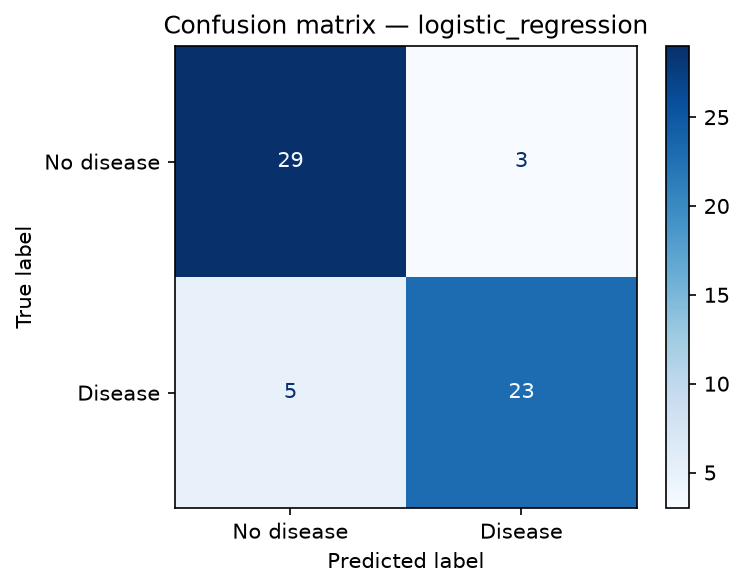

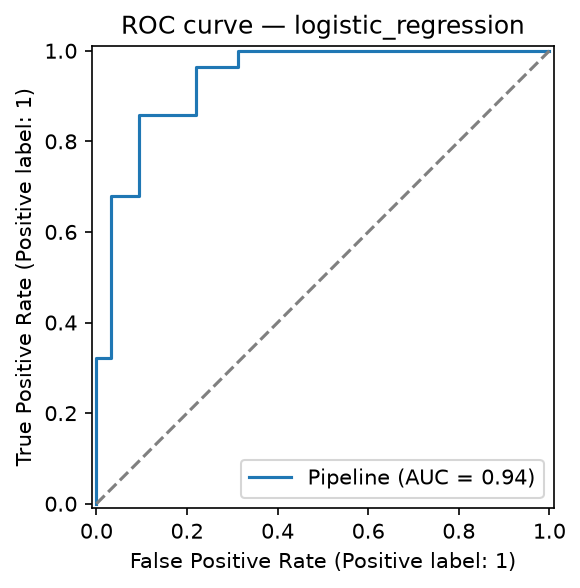

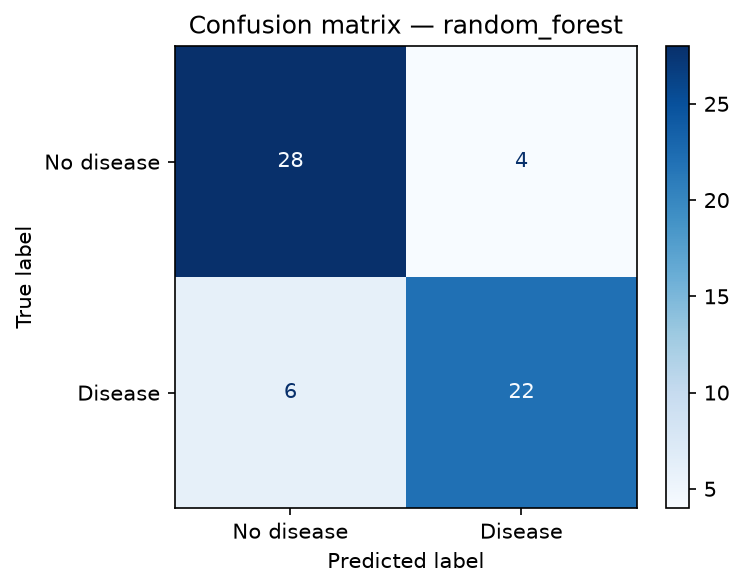

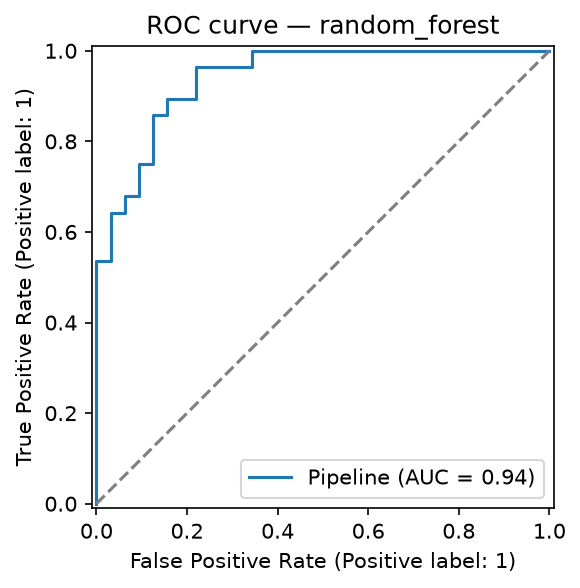

In [10]:
for name in MODEL_SPECS:
    for kind in ("confusion_matrix", "roc_curve"):
        p = ROOT / "screenshots" / "training" / f"{name}_{kind}.png"
        if p.exists():
            display(Image(filename=str(p), width=380))